In [4]:
import pandas as pd 

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
print(df.shape)


(150, 6)


In [ ]:
print(df.describe())
print(df.info())


(150, 6)
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    fl

In [11]:
print(df.isna().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


Dataset is clean

In [8]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [13]:
print(df['Species'].value_counts())

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [16]:
drop_duplicates = df.drop_duplicates(subset="Species")
drop_duplicates




,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
50,51,7.0,3.2,4.7,1.4,Iris-versicolor
100,101,6.3,3.3,6.0,2.5,Iris-virginica


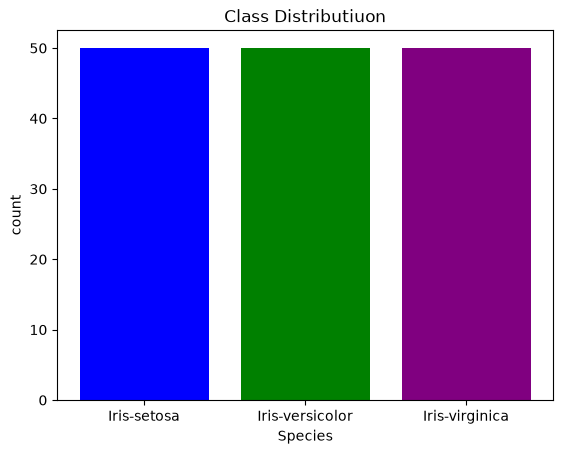

In [19]:
import matplotlib.pyplot as plt 

counts = df["Species"].value_counts()

plt.bar(counts.index, counts.values, color = ['blue','green','purple'])
plt.xlabel("Species")
plt.ylabel("count")
plt.title("Class Distributiuon")
plt.show()

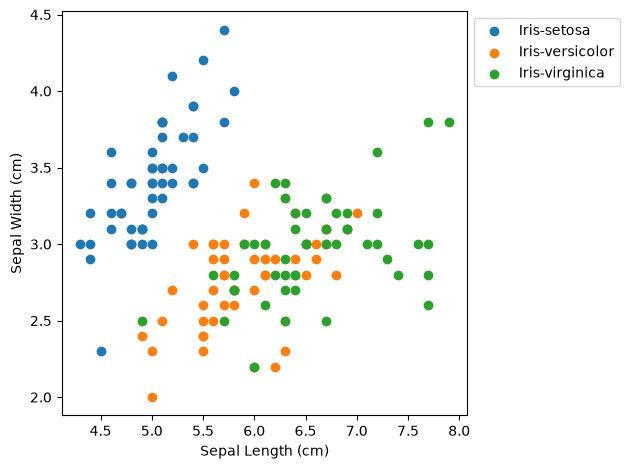

In [26]:
import matplotlib.pyplot as plt

for species, group in df.groupby("Species"):
    plt.scatter(group["SepalLengthCm"], group["SepalWidthCm"], label=species)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.legend(bbox_to_anchor=(1, 1), loc=2)
plt.tight_layout()   
plt.show()

Species Setosa has smaller sepal lengths but larger sepal widths.
Versicolor Species lies in the middle of the other two species in terms of sepal length and width
Species Virginica has larger sepal lengths but smaller sepal widths.

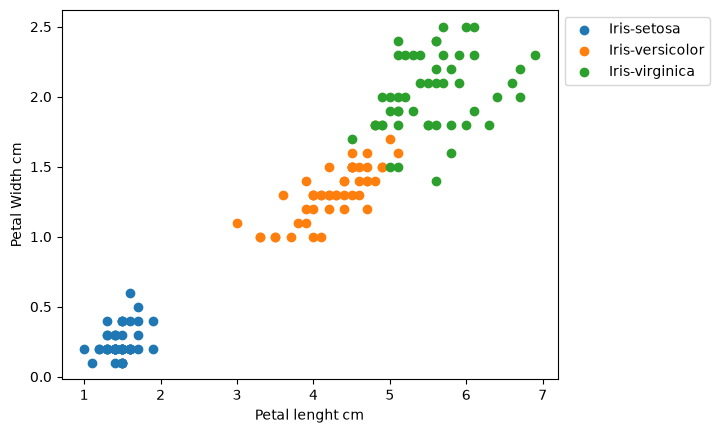

In [28]:
for species, group in df.groupby("Species"):
    plt.scatter(group["PetalLengthCm"], group["PetalWidthCm"], label=species)

plt.xlabel("Petal lenght cm")
plt.ylabel("Petal Width cm")
plt.legend(bbox_to_anchor=(1, 1),loc=2)
plt.show()

In [ ]:
Species Setosa has smaller petal lengths and widths.
Versicolor Species lies in the middle of the other two species in terms of petal length and width
Species Virginica has the largest of petal lengths and widths.

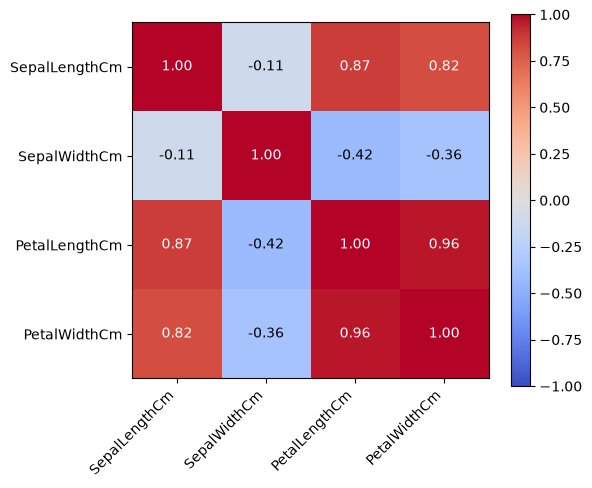

In [30]:
import matplotlib.pyplot as plt
import numpy as np

corr = df.select_dtypes(include=['number']).corr(method='pearson')
corr = corr.drop(['Id'], axis=1).drop(['Id'], axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(np.arange(len(corr.columns)))
ax.set_yticks(np.arange(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        val = corr.iloc[i, j]
        color = 'white' if abs(val) > 0.6 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=color)

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()